In [564]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from kneed import KneeLocator
import seaborn as sns

In [565]:
bowlingStats=pd.read_csv("BowlingStatsKmeans.csv")
#bowlingStats=bowlingStats[bowlingStats.Year==2021]
bowlingStats=bowlingStats[["Player","Mat", "Inns","Ov","Runs","Wkts","Avg","Econ","SR"]].groupby(["Player"],as_index=False).agg({'Mat':'sum','Inns':'sum','Ov':'sum','Runs':'sum','Wkts':'sum','Avg':'mean','Econ':'mean','SR':'mean'})
bowlingStatistics=bowlingStats.copy()
bowlingStats[1:]

,Player,Mat,Inns,Ov,Runs,Wkts,Avg,Econ,SR
1,Abhishek Sharma,19,14,22.0,176,7,27.500,8.666667,19.0000
2,Adam Milne,4,4,14.0,131,3,43.660,9.350000,28.0000
3,Adam Zampa,3,3,11.0,92,2,46.000,8.360000,33.0000
4,Adil Rashid,1,1,3.0,35,0,0.000,11.660000,0.0000
5,Aiden Markram,6,2,4.0,23,0,0.000,5.750000,0.0000
...,...,...,...,...,...,...,...,...,...
180,Wanindu Hasaranga,2,2,6.0,60,0,0.000,10.000000,0.0000
181,Washington Sundar,31,31,95.0,682,19,35.770,7.787500,28.2500
182,Yusuf Pathan,25,2,3.0,22,1,7.000,7.500000,6.0000
183,Yuvraj Singh,8,2,2.0,23,0,0.000,11.500000,0.0000


In [566]:
bowlingStats=bowlingStats[(bowlingStats['Ov'] > 8.0) & (bowlingStats['Mat']>3) & (bowlingStats['Wkts']>8)]
bowlingStats = bowlingStats.drop(columns=['Mat','Ov','Inns'])
bowlingStatsOrig=bowlingStats.copy()
bowlingStats


,Player,Runs,Wkts,Avg,Econ,SR
9,Amit Mishra,715,32,22.175000,7.215000,18.577500
10,Andre Russell,1005,41,24.910000,9.625000,15.567500
11,Andrew Tye,731,28,48.773333,10.363333,27.333333
12,Ankit Rajpoot,574,16,56.810000,9.906667,32.423333
14,Anrich Nortje,699,34,19.425000,7.275000,15.895000
...,...,...,...,...,...,...
173,Umesh Yadav,872,28,22.423333,9.836667,14.773333
176,Varun Chakaravarthy,839,36,26.940000,8.360000,19.670000
178,Vijay Shankar,310,9,45.457500,8.915000,29.937500
181,Washington Sundar,682,19,35.770000,7.787500,28.250000


In [562]:
bowlingStats=bowlingStats.to_numpy()

In [536]:
bowlingStatsNoLabel=bowlingStats[:,1:]
bowlingStatsNoLabel
scaler = StandardScaler()
scaled_features = scaler.fit_transform(bowlingStatsNoLabel)
scaled_features

array([[-1.40692702e-01,  2.60031915e-01, -8.69140642e-01,
        -1.29688669e+00, -5.50101227e-01],
       [ 5.86384793e-01,  7.88285725e-01, -6.41430505e-01,
         1.08131901e+00, -9.24156767e-01],
       [-1.00578082e-01,  2.52524431e-02,  1.34537860e+00,
         1.80991176e+00,  5.37994443e-01],
       [-4.94202794e-01, -6.79085971e-01,  2.01449394e+00,
         1.35926974e+00,  1.17053355e+00],
       [-1.80807322e-01,  3.77421650e-01, -1.09809965e+00,
        -1.23767825e+00, -8.83458033e-01],
       [-2.56022236e-01,  1.42642179e-01, -5.07662942e-01,
         7.73764052e-01, -7.74306721e-01],
       [-1.13113901e-01,  2.52524431e-02, -1.26357456e+00,
         1.10598919e+00, -1.49953124e+00],
       [ 1.11288919e+00,  5.53506254e-01,  7.35445687e-01,
        -1.36843022e+00,  1.33539967e+00],
       [-1.40430324e+00, -1.08995005e+00, -7.63819500e-01,
         1.49084405e+00, -1.11895147e+00],
       [-2.83601037e-01, -6.79085971e-01,  3.31228973e-01,
         1.86089681e+00

In [537]:
pca = PCA(n_components=2)
principalComponents = pca.fit_transform(scaled_features)
principalComponents.shape

(86, 2)

In [538]:
silhouette_coefficients = []
kmeans_kwargs = {"init": "random","n_init": 10,"max_iter": 500,"random_state":40}
for k in range(2, 11):
    kmeans = KMeans(n_clusters=k, **kmeans_kwargs)
    kmeans.fit(scaled_features)
    score = silhouette_score(scaled_features, kmeans.labels_)
    silhouette_coefficients.append(score)


In [539]:
silhouette_coefficients

[0.28774980229087394,
 0.3142838802298707,
 0.26230648711030075,
 0.25266083155127467,
 0.2558164549122578,
 0.28444325080216265,
 0.30856760097341956,
 0.27818566202910544,
 0.27518970323401387]

In [540]:
sse = []
for k in range(1, 11):
    kmeans = KMeans(n_clusters=k, **kmeans_kwargs)
    kmeans.fit(scaled_features)
    sse.append(kmeans.inertia_)
sse

[429.99999999999983,
 303.0630346512727,
 214.67304554761733,
 178.78939606769595,
 152.5876053247314,
 136.12344231873593,
 112.19816450728038,
 96.85061320096283,
 91.16152547236652,
 81.42188729245764]

In [541]:
kl = KneeLocator(range(1, 11), sse, curve="convex", direction="decreasing" )
kl.elbow

3

In [542]:
clusters=7
kmeans = KMeans(n_clusters=clusters, **kmeans_kwargs)
kmeans.fit(scaled_features)
labels=kmeans.labels_
labels

array([1, 1, 0, 0, 1, 1, 1, 6, 4, 0, 6, 5, 4, 1, 4, 2, 4, 1, 5, 4, 1, 1,
       5, 4, 5, 4, 4, 2, 6, 1, 5, 2, 4, 0, 4, 1, 5, 3, 6, 3, 4, 4, 5, 4,
       0, 4, 5, 5, 4, 2, 6, 0, 4, 5, 5, 5, 0, 5, 1, 6, 6, 5, 2, 5, 6, 6,
       1, 4, 6, 4, 0, 5, 2, 5, 1, 1, 6, 5, 3, 0, 2, 1, 1, 0, 5, 2])

In [543]:
df1 = pd.DataFrame({'Component1':principalComponents[:,0], 'Component2':principalComponents[:,1],"Cluster_Kmeans":labels,'Player':bowlingStats[:,0]})
df1

,Component1,Component2,Cluster_Kmeans,Player
0,-1.087183,-0.433404,1,Amit Mishra
1,-1.067827,-0.612224,1,Andre Russell
2,1.408819,0.525952,0,Andrew Tye
3,2.423350,0.940461,0,Ankit Rajpoot
4,-1.356047,-0.743597,1,Anrich Nortje
...,...,...,...,...
81,-0.555427,-1.234232,1,Umesh Yadav
82,-0.793935,-0.205269,1,Varun Chakaravarthy
83,2.109888,0.071856,0,Vijay Shankar
84,0.553591,0.433174,5,Washington Sundar


In [544]:
processedBowlingStats=bowlingStatistics.copy()
processedBowlingStats=pd.merge(processedBowlingStats,df1,on="Player",how="left").dropna()
processedBowlingStats["Cluster_Kmeans"] = processedBowlingStats["Cluster_Kmeans"].astype(int)
processedBowlingStats.columns
for i in range(0,clusters):
    print("Cluster Number ", i)
    temp=processedBowlingStats[processedBowlingStats["Cluster_Kmeans"] == i]
    display(temp[["Player","Wkts","Avg","Econ","SR","Cluster_Kmeans"]])

Cluster Number  0


,Player,Wkts,Avg,Econ,SR,Cluster_Kmeans
11,Andrew Tye,28,48.773333,10.363333,27.333333,0
12,Ankit Rajpoot,16,56.810000,9.906667,32.423333,0
24,Ben Stokes,16,36.592500,10.415000,22.395000,0
84,Kartik Tyagi,13,35.885000,9.230000,23.220000,0
105,Marcus Stoinis,20,48.190000,9.900000,29.797500,0
116,Mohit Sharma,9,39.333333,10.366667,22.473333,0
124,Navdeep Saini,17,33.083333,9.853333,23.946667,0
153,Shahbaz Nadeem,11,42.565000,9.455000,26.850000,0
170,Tom Curran,13,38.330000,10.736667,21.163333,0
178,Vijay Shankar,9,45.457500,8.915000,29.937500,0


Cluster Number  1


,Player,Wkts,Avg,Econ,SR,Cluster_Kmeans
9,Amit Mishra,32,22.175000,7.215000,18.577500,1
10,Andre Russell,41,24.910000,9.625000,15.567500,1
14,Anrich Nortje,34,19.425000,7.275000,15.895000,1
17,Arshdeep Singh,30,26.516667,9.313333,16.773333,1
18,Avesh Khan,28,17.437500,9.650000,10.937500,1
32,Chris Morris,42,28.835000,8.820000,19.225000,1
45,Dwayne Bravo,45,29.212500,8.587500,20.197500,1
52,Hardik Pandya,32,24.505000,9.045000,16.215000,1
56,Harshal Patel,44,30.337500,9.057500,19.890000,1
74,Jofra Archer,46,22.120000,7.223333,18.560000,1


Cluster Number  2


...

,Player,Wkts,Avg,Econ,SR,Cluster_Kmeans
23,Ben Laughlin,9,23.440000,10.040000,14.000000,4
31,Chris Jordan,13,19.256667,8.466667,13.000000,4
33,Chris Woakes,13,20.075000,8.905000,13.475000,4
44,Dhawal Kulkarni,10,25.707500,9.592500,16.187500,4
51,Harbhajan Singh,23,19.356667,8.190000,14.593333,4
58,Ish Sodhi,9,21.875000,7.600000,19.175000,4
65,James Pattinson,11,29.090000,9.010000,19.360000,4
67,Jason Holder,30,16.035000,8.035000,11.965000,4
83,Karn Sharma,10,29.416667,9.893333,18.016667,4
85,Keemo Paul,9,26.330000,8.720000,18.110000,4


Cluster Number  5


,Player,Wkts,Avg,Econ,SR,Cluster_Kmeans
28,Chetan Sakariya,14,30.420000,8.190000,22.280000,5
48,Glenn Maxwell,11,42.576667,8.240000,31.066667,5
57,Imran Tahir,35,32.975000,6.670000,28.375000,5
60,Ishant Sharma,14,41.280000,8.106667,31.076667,5
75,Josh Hazlewood,12,45.315000,7.385000,39.545000,5
87,Kieron Pollard,9,33.250000,8.125000,23.650000,5
98,Lockie Ferguson,21,44.463333,8.560000,28.223333,5
110,Mitchell McClenaghan,17,35.520000,8.090000,26.570000,5
112,Moeen Ali,16,32.330000,7.217500,26.665000,5
120,Murugan Ashwin,19,47.290000,7.835000,34.925000,5


Cluster Number  6


,Player,Wkts,Avg,Econ,SR,Cluster_Kmeans
19,Axar Patel,37,41.4475,7.142500,33.7500,6
25,Bhuvneshwar Kumar,31,40.9050,7.605000,32.0825,6
71,Jaydev Unadkat,29,45.7450,9.462500,29.3375,6
89,Krunal Pandya,35,41.9750,7.475000,33.2600,6
115,Mohammed Siraj,40,31.3300,8.490000,22.4175,6
131,Prasidh Krishna,30,47.6250,9.275000,30.7000,6
135,Rahul Chahar,41,25.6700,7.366667,20.9100,6
140,Ravichandran Ashwin,45,36.2525,7.607500,28.5525,6
141,Ravindra Jadeja,45,32.5025,7.387500,25.7250,6
148,Sandeep Sharma,41,37.8625,7.907500,28.1525,6


c:\users\rajee\appdata\local\programs\python\python38\lib\site-packages\seaborn\regression.py:581: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


<Figure size 1440x1440 with 0 Axes>

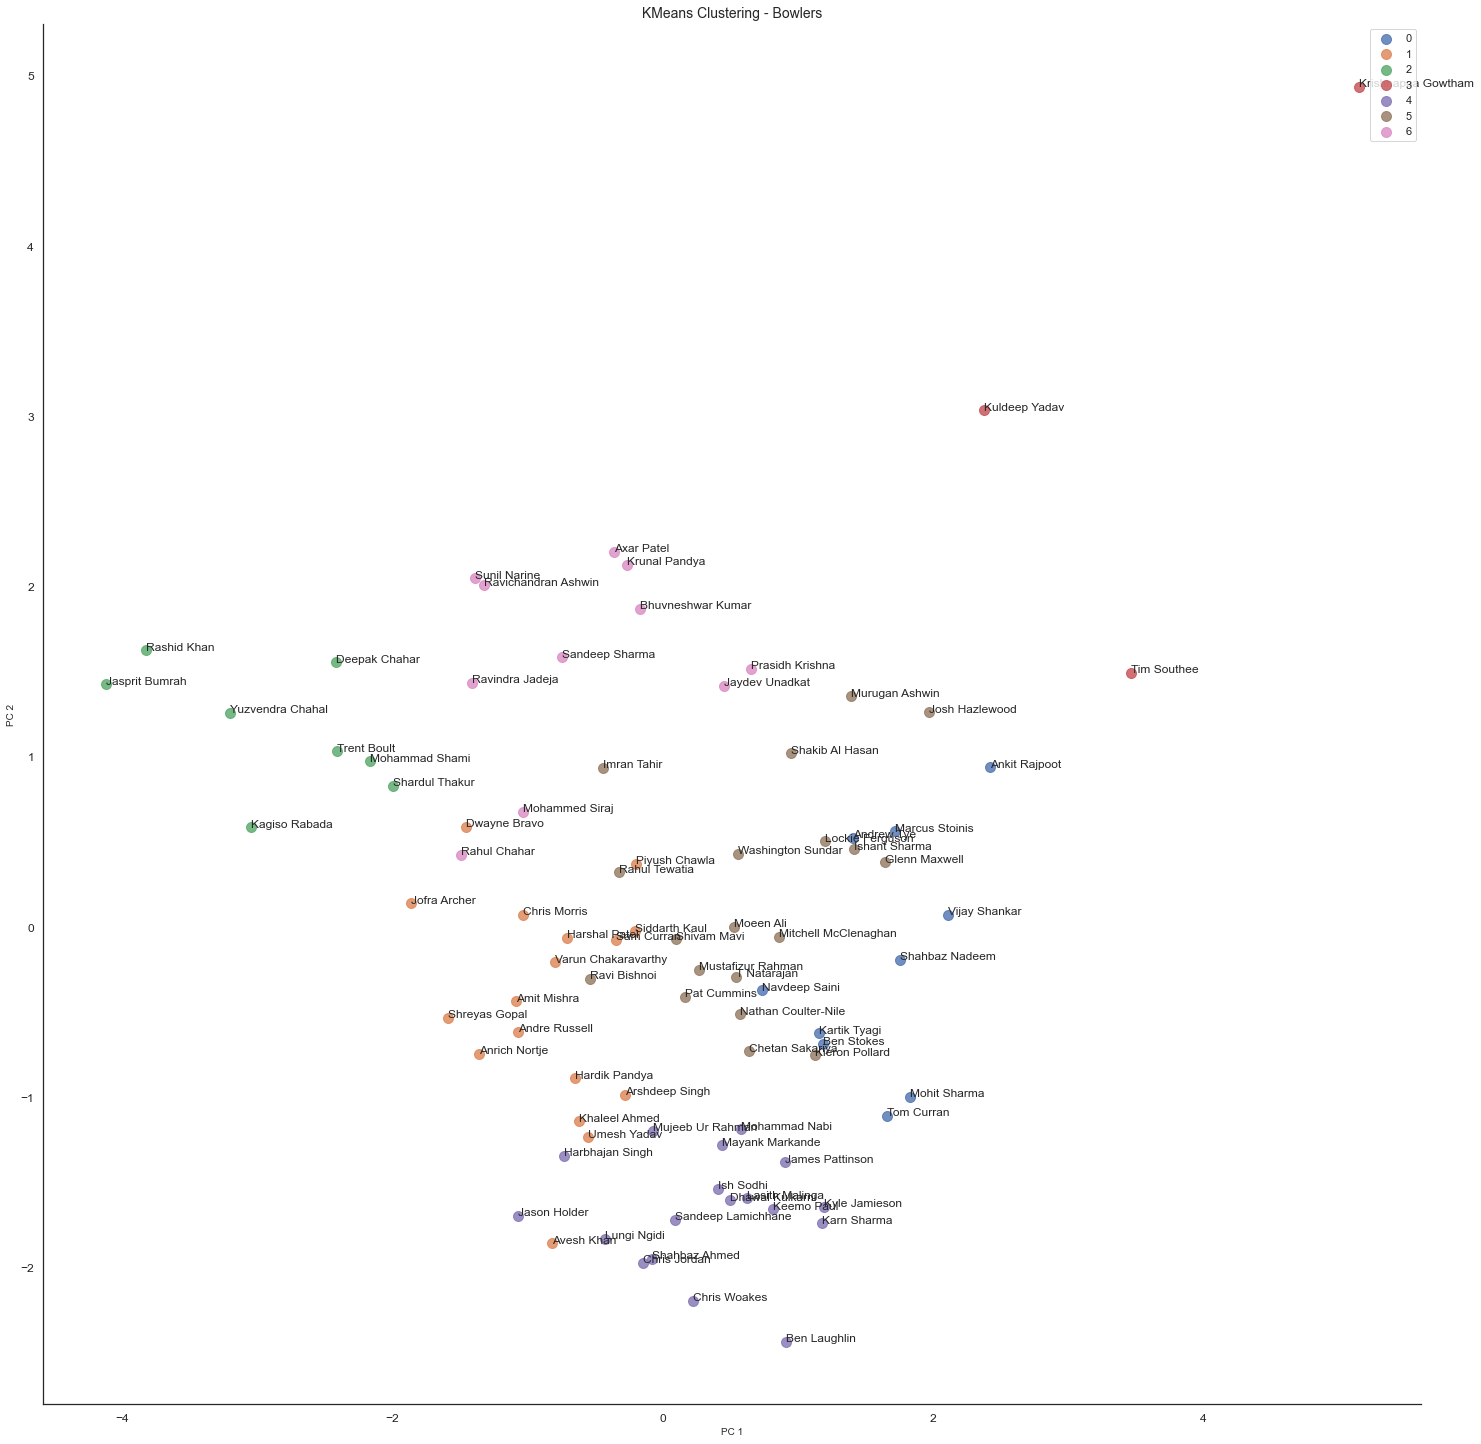

In [545]:
sns.set(style="white")
plt.figure(figsize=(20,20))
ax = sns.lmplot(x="Component1", y="Component2", hue='Cluster_Kmeans', data = df1, legend=False,
fit_reg=False, size = 20, scatter_kws={"s": 100})
texts = []
for x, y, s in zip(df1.Component1, df1.Component2,df1.Player):
    texts.append(plt.text(x, y, s))
#ax.set(ylim=(2, 2))
plt.tick_params(labelsize=12)
plt.title("KMeans Clustering - Bowlers",fontsize = 14 ) #title
plt.xlabel("PC 1", fontsize = 10)
plt.ylabel("PC 2", fontsize = 10)
plt.legend()
plt.show()

c:\users\rajee\appdata\local\programs\python\python38\lib\site-packages\seaborn\regression.py:581: UserWarning: The `size` parameter has been renamed to `height`; please update your code.
  warnings.warn(msg, UserWarning)


<Figure size 1440x1440 with 0 Axes>

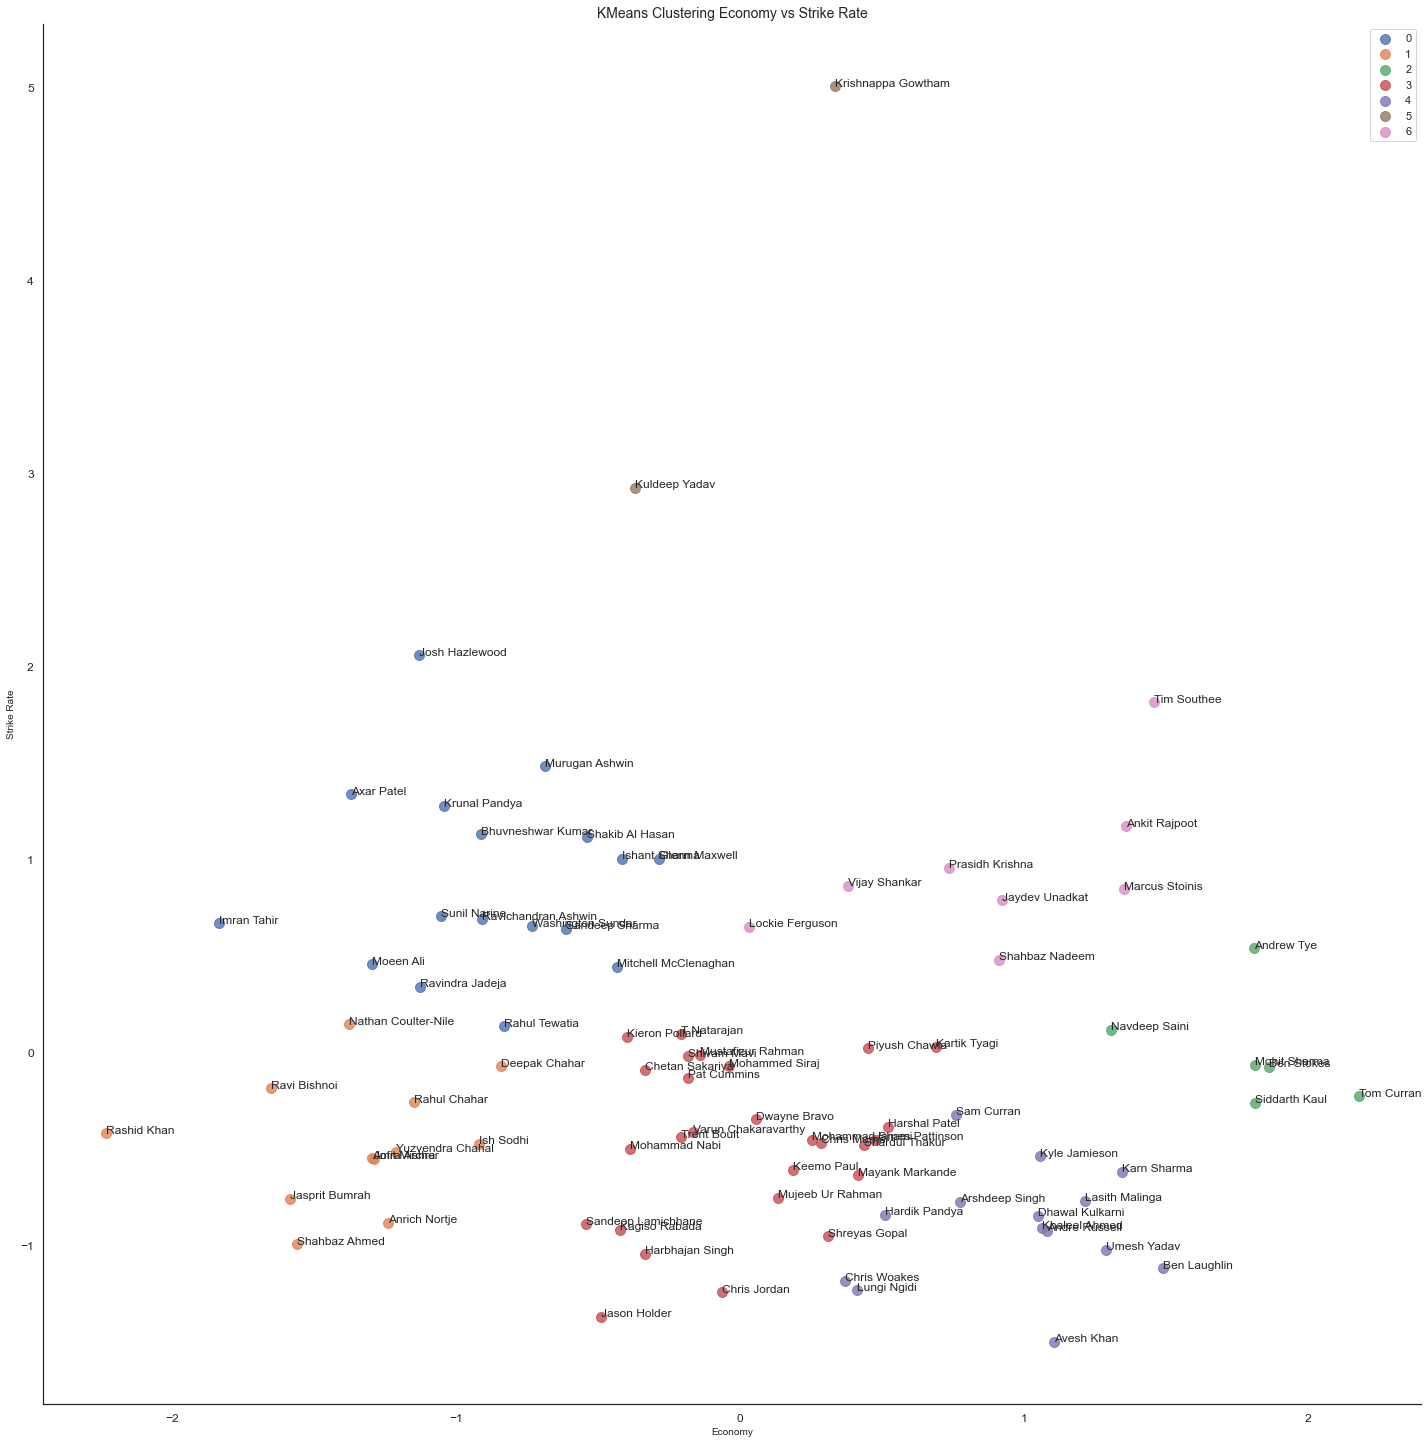

In [567]:
bowlingStatsOrig=bowlingStatsOrig.drop(columns=["Runs","Wkts","Avg"]).to_numpy()
bowlingStatsNoLabel=bowlingStatsOrig[:,1:]
bowlingStatsNoLabel
scaler = StandardScaler()
scaled_features = scaler.fit_transform(bowlingStatsNoLabel)
clusters=7
kmeans = KMeans(n_clusters=clusters, **kmeans_kwargs)
kmeans.fit(scaled_features)
labels=kmeans.labels_
df1 = pd.DataFrame({'Economy':scaled_features[:,0], 'StrikeRate':scaled_features[:,1],"Cluster_Kmeans":labels,'Player':bowlingStatsOrig[:,0]})
sns.set(style="white")
plt.figure(figsize=(20,20))
ax = sns.lmplot(x="Economy", y="StrikeRate", hue='Cluster_Kmeans', data = df1, legend=False,
fit_reg=False, size = 20, scatter_kws={"s": 100})
texts = []
for x, y, s in zip(df1.Economy, df1.StrikeRate,df1.Player):
    texts.append(plt.text(x, y, s))
#ax.set(ylim=(2, 2))
plt.tick_params(labelsize=12)
plt.title("KMeans Clustering Economy vs Strike Rate",fontsize = 14 ) #title
plt.xlabel("Economy", fontsize = 10)
plt.ylabel("Strike Rate", fontsize = 10)
plt.legend()
plt.show()